In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.append('../../../code/')
import utils
import leakage
import reframed
import scipy
import statsmodels.api as sm
import seaborn as sns

# Estimate release rates for E. coli in glucose from Paczia et al. 2012

In [69]:
data_folder = Path('../../../data')
supp_figure_folder = Path('../../../SupplementalFigures')
figure_folder = Path('../../../Figures')
organism = 'e_coli'
exometabolites_folder = data_folder / 'paczia_2012' /f"{organism}"
fn_OD = exometabolites_folder / "{0}_OD.csv".format(organism)

In [70]:
# Use same value as for galactose -> also reasonably similiar to this literature value
# https://bionumbers.hms.harvard.edu/bionumber.aspx?s=n&v=2&id=109837
# Slightly lower than https://bmcbiophys.biomedcentral.com/articles/10.1186/2046-1682-6-4/tables/1

gDW_per_OD = 0.346 

In [71]:
concentrations, concentrations_std = leakage.get_concentrations(exometabolites_folder, 'e_coli')

In [72]:
fn_glucose = exometabolites_folder / "{0}_glucose.csv".format(organism)
glucose_df = pd.read_csv(fn_glucose)

## Remove outliers

In [73]:
concentrations.loc[1, 'FUM'] = np.nan

# Read in OD values

In [74]:
df_OD = pd.read_csv(fn_OD, index_col=0)


Text(0, 0.5, 'ln(OD600)')

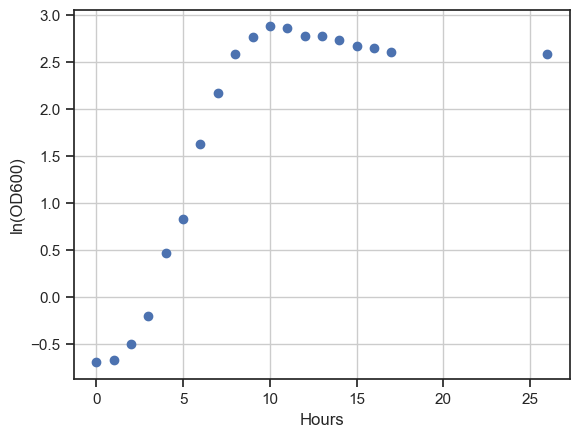

In [75]:
plt.scatter(df_OD.index, np.log(df_OD['OD mean']))
plt.grid()
plt.xlabel('Hours')
plt.ylabel('ln(OD600)')

Text(0, 0.5, 'ln(OD600)')

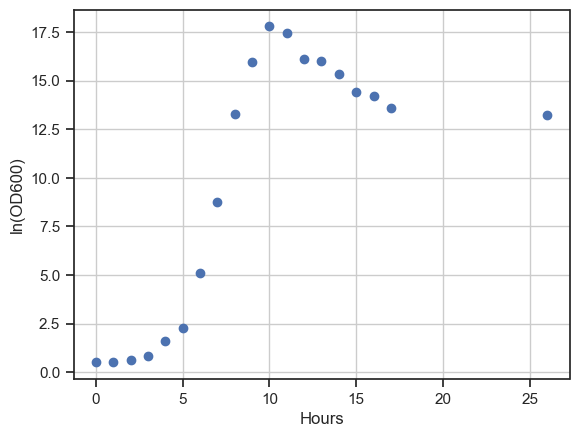

In [76]:
plt.scatter(df_OD.index, df_OD['OD mean'])
plt.grid()
plt.xlabel('Hours')
plt.ylabel('ln(OD600)')

## Mapping

In [77]:
mapping_df = pd.read_csv(data_folder / 'this_project/5_div/5B_id_mapping.csv', index_col=0)
met_abrv_to_id = mapping_df['Ecoli metabolite'].to_dict()
met_abrv_to_name = mapping_df['Metabolite name'].to_dict()
met_name_to_abrv = {value:key for key, value in met_abrv_to_name.items()}


# Estimate biomass area under the curve (AUC)

## Simpson integration

In [78]:
xt = np.zeros(len(df_OD)-1)
for i in range(1, len(df_OD)-1):
    xt[i] = scipy.integrate.simpson(df_OD.loc[:i, 'OD mean'].values, x = df_OD.index[:i+1])
    print(i, df_OD.loc[i, 'OD mean'], xt[i]*gDW_per_OD)

1 0.514 0.175422
2 0.608 0.3649146666666666
3 0.817 0.6081238333333333
4 1.595 0.9959033333333331
5 2.295 1.6711223333333332
6 5.085 2.8250899999999994
7 8.765 5.195478333333333
8 13.3 8.98908
9 15.94 14.102239166666665
10 17.78 19.92729333333333
11 17.45 26.084651666666666
12 16.1 31.88505333333333
13 15.99 37.40087
14 15.34 42.88785333333333
15 14.43 48.04556
16 14.21 52.952993333333325
17 13.61 57.77680999999999


In [79]:
x = pd.Series(xt*gDW_per_OD, index = df_OD.index[:-1])


In [80]:

df_auc = pd.DataFrame(x, columns = ['AUC'])
df_auc['OD'] = df_OD.loc[:18, 'OD mean'].values
df_auc.to_csv(data_folder / 'paczia_2012' /f"{organism}"/ 'auc_ecoli.csv')

In [81]:
auc_end_exp_phase = df_auc.loc[10, 'AUC']

In [82]:
# concentrations.to_csv(data_folder / 'paczia_2012' /f"{organism}"/'conc_ecoli.csv')
# concentrations_std.to_csv(data_folder / 'paczia_2012' /f"{organism}"/'conc_std_ecoli.csv')

Text(0, 0.5, 'Cumulative gDW')

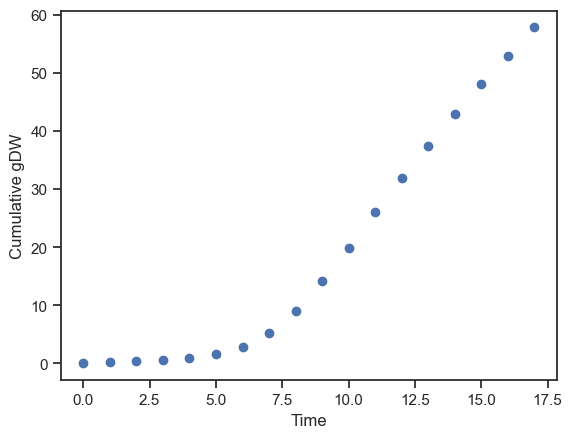

In [83]:
plt.scatter(df_OD.index[:-1], x)
plt.xlabel('Time')
plt.ylabel('Cumulative gDW')

# Estimate rate by linear regression on initial timepoints for each metabolite
The time limits is determined by inspection of the time-series of each metabolite

In [84]:
specific_limits = {
    'G6P': (1, 10),
    'F6P': (1, 10),
    'FBP': (7, 10),
    'DHAP': (1, 10),
    'GA3P': (1, 10),
    '23PG': (1, 10),
    'PEP': (3, 10),
    'R5P': (1, 10),
    'RU5P+X5P': (3, 10),
    'E4P': (6, 10),
    'CIT': (1, 10),
    'ACN': (1, 10),
    'ICIT': (1, 10),
    'OAS': (1, 7),
    'GLU': (1, 10),
    'SER': (1, 10),
    'ASP': (1, 10),
    'THR': (1, 10),
    'HOM': (1, 10),
    'TYR': (1, 10),
    'GLY': (1, 10),
    'PRO': (1, 8),
    'ALA': (1, 9),
    'MET': (1, 9),
    'VAL': (1, 9),
    'PHE': (1, 10),
    'ILEU': (1, 10),
    'LEU': (1, 10),
    'TRP': (1, 6),
    'HIS': (1, 6),
    'ARG': (1, 7),
    'PYR': (1, 8),
    'ORO': (1, 8),
    'FUM': (3, 8),
    'URA': (1, 10),
    'AKG': (7, 10),
    'ACT': (1, 8)
}

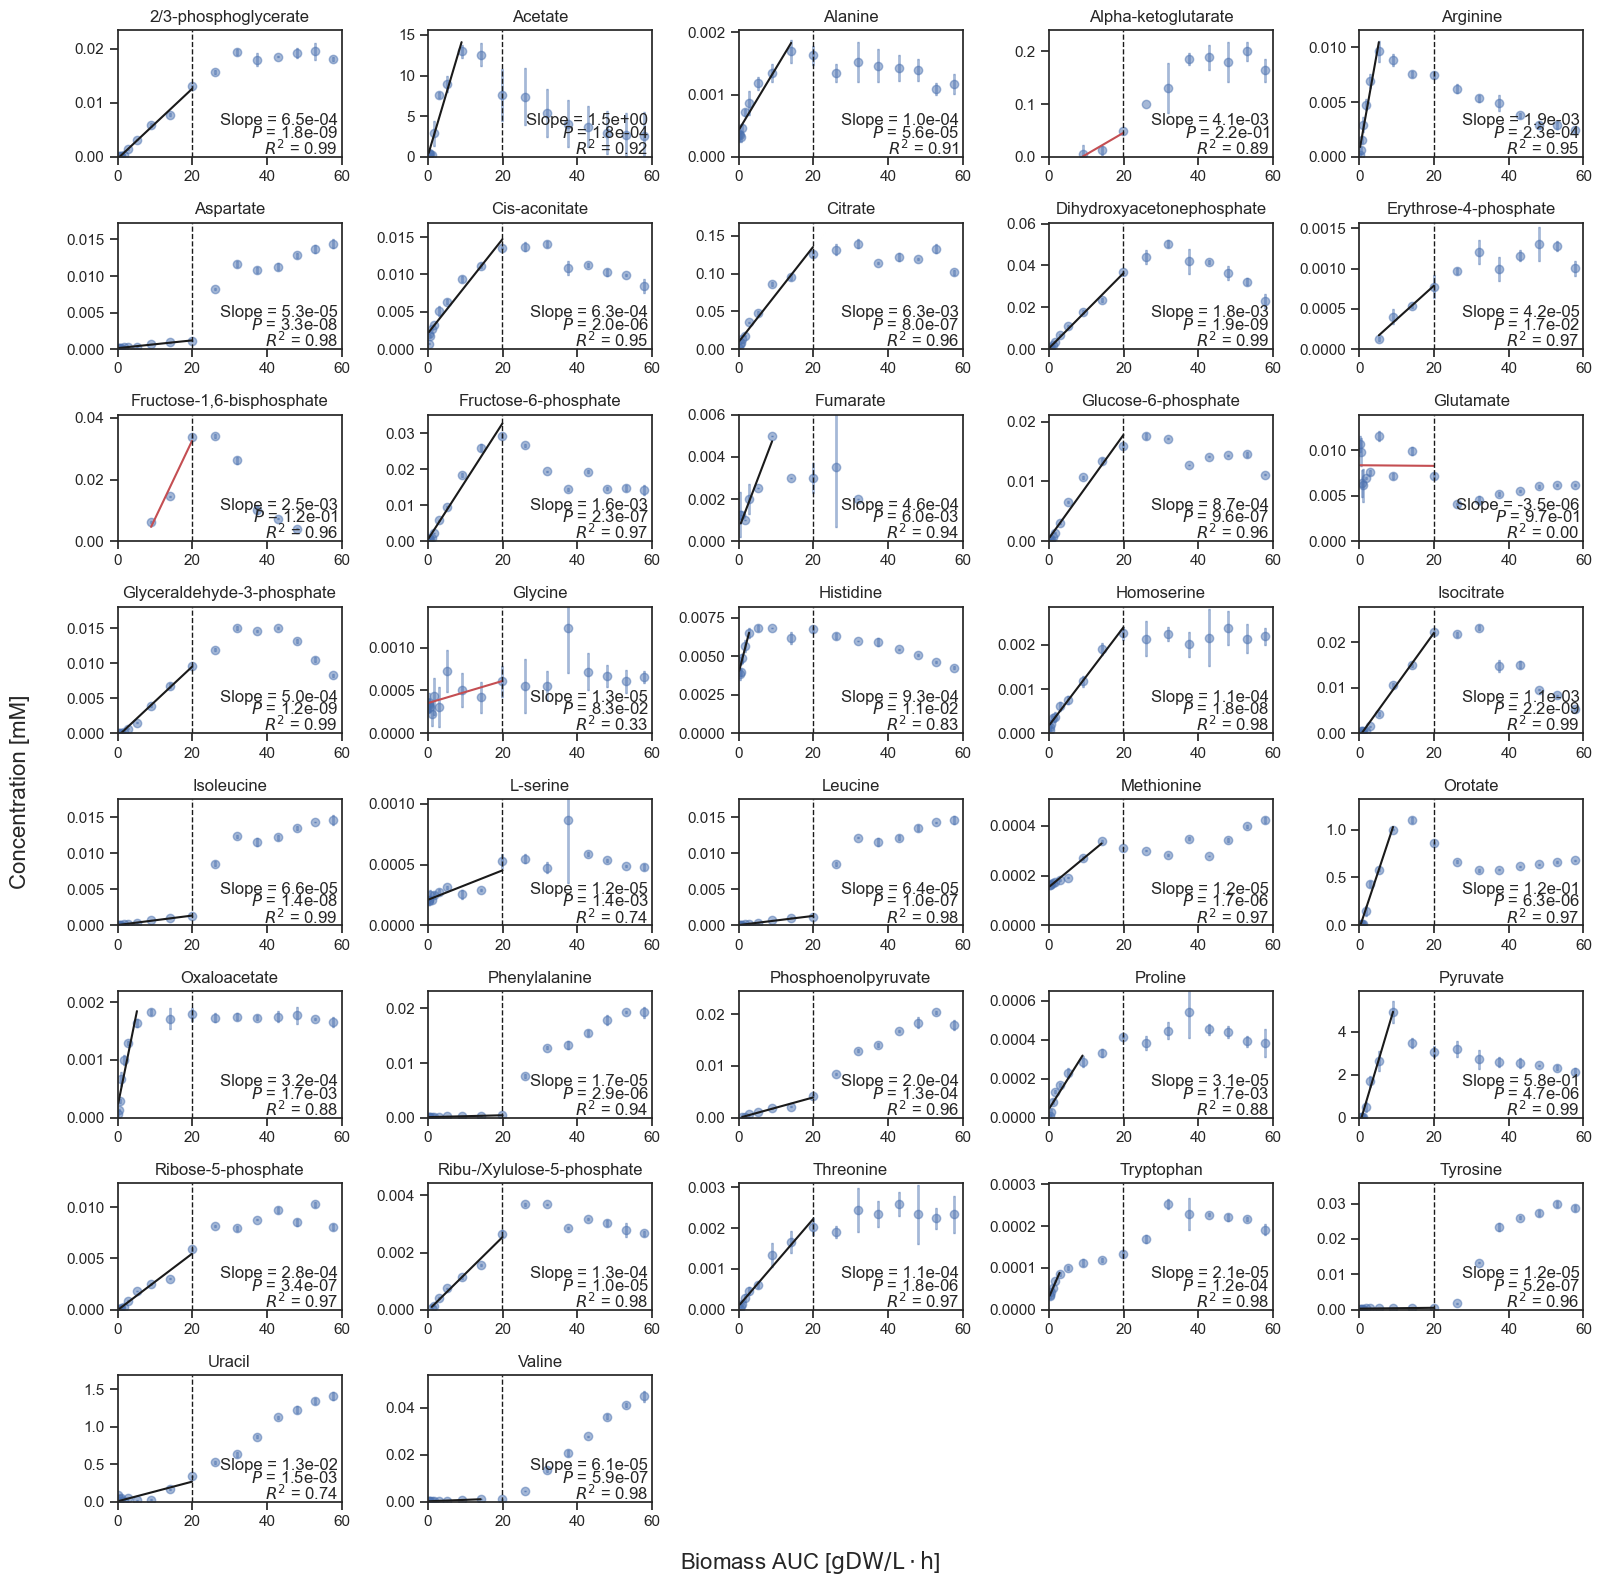

In [85]:
rate_dict_m = {}
fig, axes = plt.subplots(8,5, figsize = (16, 16), sharex = False)
axes = axes.flatten()
fun = lambda x, a ,b: x*a+b
data_list = []
metabolite_names = sorted([met_abrv_to_name[c] for c in concentrations.columns])
for i,metabolite in enumerate(metabolite_names):
    c = met_name_to_abrv[metabolite]
    conc = concentrations[c][:-1]*1e-3 # Convert from uM to mM #
    conc_std = concentrations_std[c][:-1]*1e-3
    lim = specific_limits[c]
    conc[conc==0] = np.nan
    idx = ((concentrations.index >= lim[0]) & (concentrations.index <= lim[1]))[:-1] & np.isfinite(conc)
    rate_conc = conc[idx]

    ax = axes[i]
    ax.errorbar(x, conc, yerr = conc_std, fmt='o',color='C0',capthick=1,elinewidth=2,capsize=1,  zorder = 0, alpha = 0.5)
    
    if len(rate_conc) >= 3:
        # conc[conc==0] = np.nan
        res = scipy.stats.linregress(x[idx], conc[idx])
        # print(f"R-squared: {res.rvalue**2:.6f}")
        r2 = res.rvalue**2
        data = [res.slope, res.stderr,res.pvalue, c, res.pvalue < 0.05, r2]
        x_fit = np.linspace(x[idx].min(), x[idx].max(), 3)
        y_fit = fun(x_fit, res.slope, res.intercept)
    
        if (r2 >= 0.5) & (res.pvalue < 0.05):
            ax.plot(x_fit, y_fit, 'k')
        else:
            ax.plot(x_fit, y_fit, 'r')
    else:
        data = [np.nan, np.nan, np.nan, c, np.nan, np.nan]

    data_list.append(data)
    
    ax.axvline(auc_end_exp_phase, color='k', linestyle='--', lw = 1, label='End of exponential phase')
    ax.set_title(metabolite)
    # ax.set_xlim(0, 22)
    y_max = np.max(conc)*1.2
    if np.isfinite(y_max):
        ax.set_ylim(0, y_max)
    ax.set_xlim(0, 60)
    if len(rate_conc) >= 3:
        ax.annotate(f'Slope = {res.slope:.1e}', (59, y_max*0.25), ha = 'right')
        ax.annotate(f'$P$ = {res.pvalue:.1e}', (59, y_max*0.15), ha = 'right')
        ax.annotate(f'$R^2$ = {r2:.2f}', (59, y_max*0.02), ha = 'right')
    i +=1
    # print(i)

while i<(8*5):
    axes[i].set_visible(False)
    i+=1
met_abrv_to_name
fig.supxlabel(r'Biomass AUC [$\rm{gDW/L \cdot h}$]', fontsize=16)
fig.supylabel('Concentration [mM]', x = 0, fontsize = 16)

plt.tight_layout()
plt.savefig(supp_figure_folder / 'ecoli_paczia_12_fitted_rates_manual_limits.png', dpi = 400)
plt.savefig(supp_figure_folder / 'ecoli_paczia_12_fitted_rates_manual_limits.pdf')
plt.show()

In [86]:
rate_data = pd.DataFrame(data_list, columns=['Rate [mmol/gDW/h]', 'Std. Err [mmol/gDW/h]', 'p-val', 'Metabolite abbrv.', 'Significance', 'R2'])


In [87]:
valid_pvals = rate_data['p-val'].notna()
rate_data['FDR'] = np.nan
rate_data.loc[valid_pvals, 'FDR'] = sm.stats.multipletests(rate_data.loc[valid_pvals, 'p-val'], method='fdr_bh')[1]
n_tests = rate_data['p-val'].notna().sum()
n_fdr_005 = (rate_data['FDR'] < 0.05).sum()
print(f'{n_fdr_005}/{n_tests} tests below FDR < 0.05 ({n_fdr_005 / n_tests:.1%})')
print(rate_data.loc[rate_data['p-val'].notna(), ['Metabolite abbrv.', 'p-val', 'FDR']].sort_values('FDR').to_string(index=False))

33/37 tests below FDR < 0.05 (89.2%)
Metabolite abbrv.        p-val          FDR
             23PG 1.830542e-09 2.036422e-08
             ICIT 2.201538e-09 2.036422e-08
             GA3P 1.175813e-09 2.036422e-08
             DHAP 1.863626e-09 2.036422e-08
             ILEU 1.365579e-08 1.010529e-07
              HOM 1.783298e-08 1.099701e-07
              ASP 3.279920e-08 1.733672e-07
              LEU 1.022363e-07 4.728429e-07
              F6P 2.321812e-07 9.545227e-07
              R5P 3.374006e-07 1.248382e-06
              TYR 5.248726e-07 1.765480e-06
              VAL 5.938936e-07 1.831172e-06
              CIT 8.007761e-07 2.279132e-06
              G6P 9.586334e-07 2.533531e-06
              THR 1.809851e-06 4.185280e-06
              MET 1.725148e-06 4.185280e-06
              ACN 1.994083e-06 4.340063e-06
              PHE 2.887944e-06 5.936330e-06
              PYR 4.682699e-06 9.118940e-06
              ORO 6.347390e-06 1.174267e-05
         RU5P+X5P 1.030384e-05 1.815438

In [88]:
max_conc = []
for i,metabolite in enumerate(metabolite_names):
    c = met_name_to_abrv[metabolite]
    conc = concentrations[c][:-1]*1e-3 # Convert from uM to mM #
    conc_std = concentrations_std[c][:-1]*1e-3
    lim = specific_limits[c]
    conc[conc==0] = np.nan
    idx = ((concentrations.index >= lim[0]) & (concentrations.index <= lim[1]))[:-1] & np.isfinite(conc)
    rate_conc = conc[idx]
    if rate_conc.size > 0:
        max_conc.append([metabolite, c, rate_conc.max()])
max_conc_df = pd.DataFrame(max_conc, columns=['Metabolite', 'Metabolite id', 'Max Concentration (mM)'])
max_conc_df.sort_values(by='Max Concentration (mM)', ascending=False, inplace=True) 

In [89]:
max_conc_df['Metabolite id'].values

array(['ACT', 'PYR', 'ORO', 'URA', 'CIT', 'AKG', 'DHAP', 'FBP', 'F6P',
       'ICIT', 'G6P', 'ACN', '23PG', 'GLU', 'ARG', 'GA3P', 'HIS', 'R5P',
       'FUM', 'PEP', 'RU5P+X5P', 'HOM', 'THR', 'ALA', 'OAS', 'ILEU',
       'LEU', 'ASP', 'VAL', 'E4P', 'GLY', 'TYR', 'SER', 'PHE', 'MET',
       'PRO', 'TRP'], dtype=object)

In [90]:
max_conc_df

,Metabolite,Metabolite id,Max Concentration (mM)
1,Acetate,ACT,12.948500
29,Pyruvate,PYR,4.924000
24,Orotate,ORO,0.998000
35,Uracil,URA,0.340000
7,Citrate,CIT,0.126133
3,Alpha-ketoglutarate,AKG,0.050000
8,Dihydroxyacetonephosphate,DHAP,0.036880
10,"Fructose-1,6-bisphosphate",FBP,0.033960
11,Fructose-6-phosphate,F6P,0.029293
19,Isocitrate,ICIT,0.022267


# Subset for figure 1

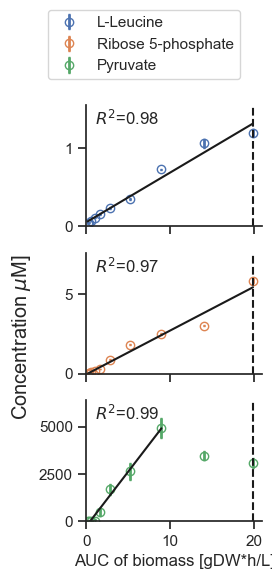

In [91]:
m_abbr_to_name = {
    'LEU': 'L-Leucine',
    'R5P': 'Ribose 5-phosphate',
    'PYR': 'Pyruvate'
}
fig, axes = plt.subplots(3,1, figsize = (3,5), sharex=True)
for i, (c, name) in enumerate(m_abbr_to_name.items()):
    conc = concentrations[c][:-1]
    conc_std = concentrations_std[c][:-1]
    lim = specific_limits[c]
    idx = ((concentrations.index >= lim[0]) & (concentrations.index <= lim[1]))[:-1]
    rate_conc = conc[idx]
    axes[i].errorbar(x, conc, yerr = conc_std, 
                     fmt='o',color=f'C{i}',capthick=1,elinewidth=2,capsize=1,
                     zorder = 0, label = name, markeredgecolor = f'C{i}', markerfacecolor = 'none')#alpha = 0.8
    res = scipy.stats.linregress(x[idx], conc[idx])
    x_fit = np.linspace(x[idx].min(), x[idx].max(), 3)
    y_fit = fun(x_fit, res.slope, res.intercept)
    
    # axes[i].set_title(name, y = 0.8, size = 10)
    axes[i].set_xlim(0, 21)
    y_max = np.max(conc[idx])*1.3
    axes[i].set_ylim(0, y_max)
    axes[i].plot(x_fit, y_fit, 'k')
    axes[i].axvline(x[10], c = 'k', ls = '--')
    
    # axes[i].annotate(f'r: {res.slope:.1e}', (1, y_max*0.9))
    # axes[i].annotate(f'p-val: {res.pvalue:.1e}', (1, y_max*0.8))
    r2 = res.rvalue**2
    axes[i].annotate(f'$R^2$={r2:.2f}', (1, y_max*0.84))
axes[i].set_xlabel('AUC of biomass [gDW*h/L]', size = 12)#, y = 0.1)
fig.supylabel(r'Concentration $\mu$M]', x = 0.1)
plt.figlegend(loc = "lower left", bbox_to_anchor = (0.2, 1))

plt.tight_layout()
sns.despine()
# plt.subplots_adjust(bottom = 0.2, left = 0.2)
plt.savefig(figure_folder / 'fitted_rates_for_fig1.pdf', bbox_inches='tight')


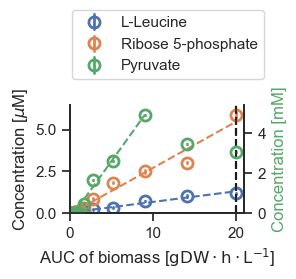

In [92]:
m_abbr_to_name = {
    'LEU': 'L-Leucine',
    'R5P': 'Ribose 5-phosphate',
    'PYR': 'Pyruvate'
}
sns.set(font_scale = 1, style = 'ticks')
fig, ax1 = plt.subplots(1,1, figsize = (3,2), sharex=True)
ax2 = ax1.twinx()
for i, (c, name) in enumerate(m_abbr_to_name.items()):
    conc = concentrations[c][:-1]
    conc_std = concentrations_std[c][:-1]
    lim = specific_limits[c]
    idx = ((concentrations.index >= lim[0]) & (concentrations.index <= lim[1]))[:-1]
    rate_conc = conc[idx]
    if i < 2:
        ax = ax1
    else:
        ax = ax2

    if name == 'Pyruvate':
        # Plot in mM
        conc = conc*1e-3
        conc_std = conc*1e-3
    ax.errorbar(x, conc, yerr = conc_std, 
                     fmt='o',color=f'C{i}',capthick=1,elinewidth=2,capsize=1,
                     zorder = 0, label = name, markeredgecolor = f'C{i}', markerfacecolor = 'none', markersize = 8, markeredgewidth = 2)#alpha = 0.8
    res = scipy.stats.linregress(x[idx], conc[idx])
    x_fit = np.linspace(x[idx].min(), x[idx].max(), 3)
    y_fit = fun(x_fit, res.slope, res.intercept)
    
    # axes[i].set_title(name, y = 0.8, size = 10)
    ax.set_xlim(0, 21)
    y_max = np.max(conc[idx])*1.1
    ax.set_ylim(0, y_max)
    ax.plot(x_fit, y_fit, c = f'C{i}', ls = '--')
    ax.axvline(x[10], c = 'k', ls = '--', zorder = 0, alpha = 0.8)
    
    # axes[i].annotate(f'r: {res.slope:.1e}', (1, y_max*0.9))
    # axes[i].annotate(f'p-val: {res.pvalue:.1e}', (1, y_max*0.8))
    r2 = res.rvalue**2
    axes[i].annotate(f'$R^2$={r2:.2f}', (1, y_max*0.84))
ax1.set_xlabel(r'AUC of biomass [$\rm{gDW \cdot h \cdot L^{-1}}$]', size = 12)#, y = 0.1)
ax1.set_ylabel(r'Concentration [$\mu$M]', size = 12)
ax2.set_ylabel(r'Concentration [mM]', size = 12, c = 'C2')
plt.figlegend(loc = "lower left", bbox_to_anchor = (0.2, 1))

plt.tight_layout()
sns.despine(top = True, right = False)
# plt.subplots_adjust(bottom = 0.2, left = 0.2)
plt.savefig(figure_folder / 'fitted_rates_for_fig1_1_panel.pdf', bbox_inches='tight')


# Glucose uptake rates

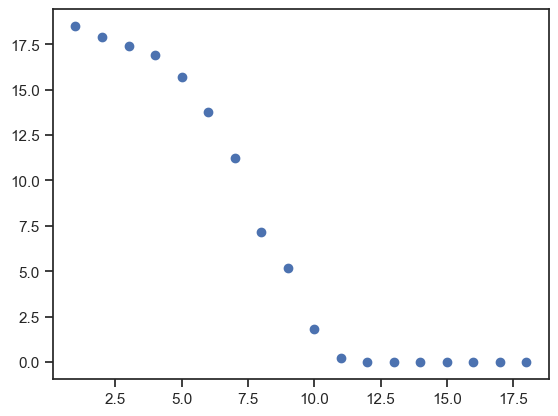

In [93]:
plt.scatter(glucose_df.index, glucose_df['Glucose mean'])

Text(0.5, 0, 'Biomass AUC [gDW*h/L]')

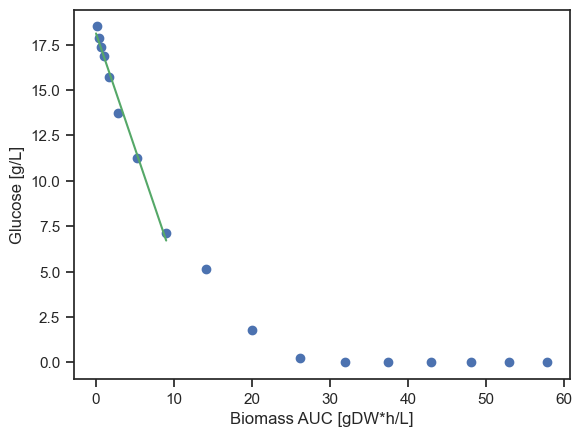

In [94]:
n = 8
res = scipy.stats.linregress(x[1:n+1], glucose_df['Glucose mean'][1:n+1])
fit = [res.slope, res.intercept]
x_fit = np.linspace(0, x[n], 3)
y_fit = fun(x_fit, *fit)
plt.plot(x_fit, y_fit, c = 'C2')
plt.scatter(x, glucose_df['Glucose mean'][:-1])
plt.ylabel('Glucose [g/L]')
plt.xlabel('Biomass AUC [gDW*h/L]')

In [95]:
glc_mw = 180.156
glc_uptake = fit[0]/glc_mw*1e3 # Converting from g/gDW/h to mmol/gDW/h
print(glc_uptake)
# print(np.sqrt(cov[0][0]))

-7.0435835942413485


# Get model

In [96]:
model_ez = reframed.load_cbmodel('../../../models/e_coli/momentiJO1366_modified.xml')
model_ez.solver = 'gurobi'

In [97]:
solution = reframed.FBA(model_ez, constraints={'R_EX_glc__D_e': (glc_uptake,0)}, shadow_prices = True)

In [98]:
solution.show_values('EX')

R_EX_ca2_e   -0.00325659
R_EX_cl_e    -0.00325659
R_EX_co2_e    16.5789
R_EX_cobalt2_e -1.56417e-05
R_EX_cu2_e   -0.000443597
R_EX_fe2_e   -0.0100488
R_EX_glc__D_e -7.04358
R_EX_h_e      5.74877
R_EX_h2o_e    33.1026
R_EX_k_e     -0.122126
R_EX_meoh_e   1.25133e-06
R_EX_mg2_e   -0.00542766
R_EX_mn2_e   -0.000432335
R_EX_mobd_e  -8.0711e-05
R_EX_nh4_e   -6.75771
R_EX_ni2_e   -0.00020209
R_EX_o2_e    -15.2438
R_EX_pi_e    -0.603537
R_EX_so4_e   -0.157799
R_EX_zn2_e   -0.000213352
R_HEX1        7.04358


In [99]:
measured_metabolites = []
for bigg_id in met_abrv_to_id.values():
    if not isinstance(bigg_id, str):
        continue
    m_ids = bigg_id.split(', ')
    for m_id in m_ids:
        if f'M_{m_id}_c' in model_ez.metabolites:
            measured_metabolites.append(f'M_{m_id}_c')

In [100]:
solution_shadow_prices = {m_id: solution.shadow_prices.get(m_id, np.nan) for m_id in measured_metabolites}

# Shadow prices

In [101]:
shadow_prices = leakage.estimate_shadow_prices_reframed(model_ez, constraints={'R_EX_glc__D_e': (glc_uptake,0)}, metabolites = measured_metabolites)

1/50: M_g6p_c, predicted flux: -7.0435835942413485, secretion reaction: R_EX_glc__D_e


### Adress uncertainty in shadow price estimates
Use uptake rate +- 20%. This is somewhat arbitrary,but is a very conservative estimate that covers different "steps" on the ladder of reduced metabolite value

In [102]:
glc_uptake_range = np.linspace(glc_uptake*1.2, glc_uptake*0.8, 5, endpoint=True)
shadow_price_list = []
for g in glc_uptake_range:
    shadow_prices_i = leakage.estimate_shadow_prices_reframed(model_ez, constraints={'R_EX_glc__D_e': (g,0)}, metabolites = measured_metabolites)
    shadow_price_list.append(shadow_prices_i)

1/50: M_g6p_c, predicted flux: -8.452300313089617, secretion reaction: R_EX_glc__D_e
1/50: M_g6p_c, predicted flux: -7.747941953665483, secretion reaction: R_EX_glc__D_e
1/50: M_g6p_c, predicted flux: -7.0435835942413485, secretion reaction: R_EX_glc__D_e
1/50: M_g6p_c, predicted flux: -6.339225234817214, secretion reaction: R_EX_glc__D_e
1/50: M_g6p_c, predicted flux: -5.6348668753930795, secretion reaction: R_EX_glc__D_e


In [103]:
shadow_price_list.append(shadow_prices)

In [104]:
df_sp_var = pd.DataFrame(shadow_price_list)

# Turnover

In [105]:
solution = reframed.pFBA(model_ez, constraints={'R_EX_glc__D_e': (glc_uptake,0)})
turnover = solution.get_metabolites_turnover(model_ez)

    

In [106]:
# The turnover of fdp is 0 because the model predicts that F6PA is used instead of FBA . Unlikely, e.g. https://bmcsystbiol.biomedcentral.com/articles/10.1186/1752-0509-7-33
solution.show_metabolite_balance('M_fdp_c', model_ez)

# Make spreadsheet

In [107]:
data = []
drop_mets = ['ru5p__L','xu5p__L'] # The D-forms is used in the pentose phosphate pathway, so we assume that it is primarily the D-forms
# 'Std. Err [mmol/gDW/h]', 'T-score', 'degrees of freedom', 'p-val', 'Metabolite abbrv.', 'Significance']
for _, row in rate_data.iterrows():
    if np.isnan(row['Rate [mmol/gDW/h]']):
        continue
    abbr = row['Metabolite abbrv.']
    rate = row['Rate [mmol/gDW/h]']
    bigg_ids = [x.strip() for x in met_abrv_to_id[abbr].split(',') if not x.strip() in drop_mets]
    if len(bigg_ids)>1:
        print(bigg_ids)
    rate_i = rate/len(bigg_ids)
    std_err_i = row['Std. Err [mmol/gDW/h]']/np.sqrt(len(bigg_ids))
    for bigg_id in bigg_ids:
        name =met_abrv_to_name[abbr]
        m_id = f'M_{bigg_id}_c'
        mv = -shadow_prices[m_id]
        m = model_ez.metabolites[m_id]
        element_dict = utils.get_element_dict(m)
        Nc = element_dict['C']
        mass = utils.get_mol_weight(m)
        mv_min = -df_sp_var.max()[m_id]
        mv_max = -df_sp_var.min()[m_id]

        mv_solver = -solution_shadow_prices[m_id]
        
        data.append([abbr, bigg_id, name, mv, mv_min, mv_max, turnover[m_id], Nc, mass, rate_i, std_err_i, row['R2'], row['p-val'], mv_solver])
df_rate = pd.DataFrame(data, columns = ['Metabolite abbrv.', 'Model ID', 'Metabolite', 
                                        'Metabolite value [gDW/mmol]','MV min', 'MV max', 
                                        'Turnover [mmol/gDW/h]', 'N carbons', 
                                        'Mol weight [g/mol]', 'Rate [mmol/gDW/h]', 'Std. Err [mmol/gDW/h]', 'R2', 'p-value', 'MV solver'])

['2pg', '3pg']
['ru5p__D', 'xu5p__D']


In [108]:
for idx, row in df_rate.iterrows():
    if row['Model ID'] == '2pg':
        print(df_rate.loc[idx, 'Metabolite'], f'Changed {idx} to 2-phosphoglycerate')
        df_rate.loc[idx, 'Metabolite'] = '2-phosphoglycerate'
        
    if row['Model ID'] == '3pg':
        print(df_rate.loc[idx, 'Metabolite'], f'Changed {idx} to 3-phosphoglycerate')
        df_rate.loc[idx, 'Metabolite'] = '3-phosphoglycerate'

    if row['Model ID'] == 'ru5p__D':
        print(df_rate.loc[idx, 'Metabolite'], f'Changed {idx} to Ribulose-5-phosphate')
        df_rate.loc[idx, 'Metabolite'] = 'Ribulose-5-phosphate'
        
    if row['Model ID'] == 'xu5p__D':
        print(df_rate.loc[idx, 'Metabolite'], f'Changed {idx} to Xylulose-5-phosphate')
        df_rate.loc[idx, 'Metabolite'] = 'Xylulose-5-phosphate'



2/3-phosphoglycerate Changed 0 to 2-phosphoglycerate
2/3-phosphoglycerate Changed 1 to 3-phosphoglycerate
Ribu-/Xylulose-5-phosphate Changed 32 to Ribulose-5-phosphate
Ribu-/Xylulose-5-phosphate Changed 33 to Xylulose-5-phosphate


In [109]:
df_rate['Species'] = 'E. coli'
df_rate['Carbon source'] = 'Glucose'
df_rate['Dataset'] = 'Paczia-12'

In [110]:
df_rate.to_csv(data_folder / 'paczia_2012' / 'paczia_12_rates_ecoli.csv')

In [118]:
import scipy.stats as st
df_rate['log10(MV)'] = np.log10(df_rate['Metabolite value [gDW/mmol]'])
df_rate['log10(Rate)'] = np.log10(df_rate['Rate [mmol/gDW/h]'])
df_rate['log10(MV solver)'] = np.log10(df_rate['MV solver'])

idx = df_rate['log10(MV)'].notna() & df_rate['log10(Rate)'].notna() & df_rate['log10(MV solver)'].notna()

mv_corr = st.pearsonr(df_rate.loc[idx,'log10(MV)'], df_rate.loc[idx, 'log10(Rate)'])
mv_solver_corr = st.pearsonr(df_rate.loc[idx, 'log10(MV solver)'], df_rate.loc[idx, 'log10(Rate)'])
print(f"Pearson correlation between log10(MV) and log10(Rate): {mv_corr[0]:.3f}, p-value: {mv_corr[1]:.3e}")
print(f"Pearson correlation between log10(MV solver) and log10(Rate): {mv_solver_corr[0]:.3f}, p-value: {mv_solver_corr[1]:.3e}")

Pearson correlation between log10(MV) and log10(Rate): -0.526, p-value: 6.994e-04
Pearson correlation between log10(MV solver) and log10(Rate): -0.540, p-value: 4.674e-04
